[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L6/BA_L6_checkloss/BA_L6_checkloss.ipynb)

# BA_L6_checkloss: The check loss

*Quantlet of Lecture 6, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

The asymmetric check loss of quantile regression for three quantile levels, and the total check loss of 20 illustrative daily peg deviations as a function of the candidate quantile: the 5% quantile is not unique when n times tau is an integer.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

## The check loss

The $\tau$-quantile minimises an asymmetric absolute loss ([Koenker & Bassett, 1978](https://doi.org/10.2307/1913643)):
$$ \rho_\tau(e) = e\,\big(\tau - \mathbb 1\{e < 0\}\big), \qquad q_\tau = \arg\min_q E\,\rho_\tau(Y - q). $$
For $\tau = 0.05$ a residual below the line costs $0.95|e|$ and one above it $0.05|e|$, so the fit is pushed to the lower tail.

**How to read the chart.** Left: $\rho_\tau(e)$ for $\tau$ = 0.05, 0.5 and 0.95. Right: the total loss $\sum_i \rho_\tau(y_i - q)$ of 20 daily deviations $y_i$ (in basis points, bp) as a function of the candidate quantile $q$; the dots mark a minimiser.
With $n = 20$ and $\tau = 0.05$, $n\tau = 1$: the loss is flat between the smallest and the second-smallest observation, so the 5% quantile is not unique.

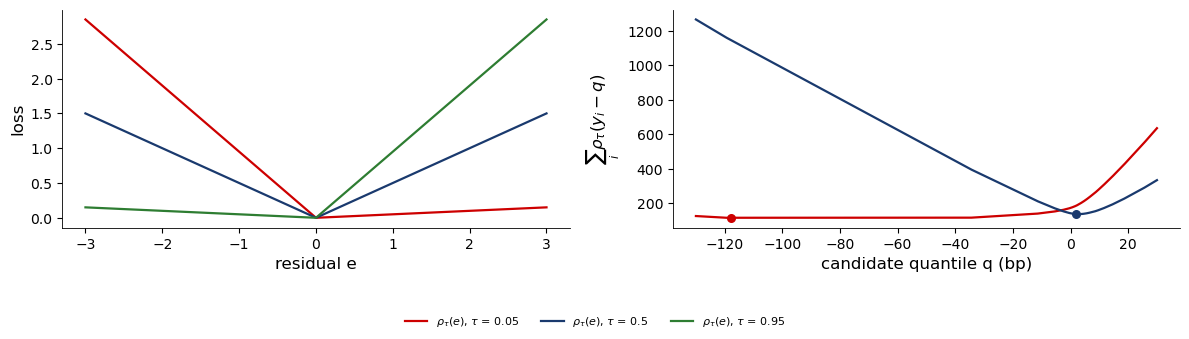

,a minimiser q (bp),minimum total loss
tau = 0.05,-117.9,116.55
tau = 0.5,2.0,137.50


In [4]:
plt.rcParams['font.size'] = 10
rho = lambda e, t: e * (t - (e < 0))
y = np.array([-120, -35, -12, -6, -3, -1, 0, 1, 2, 2, 3, 4, 5, 6, 8, 9, 11, 14, 18, 25])     # 20 daily deviations, bp
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
e = np.linspace(-3, 3, 400)
for t, col in [(0.05, RED), (0.5, BLUE), (0.95, GREEN)]:
    ax[0].plot(e, rho(e, t), color=col, lw=1.6, label=fr'$\rho_\tau(e)$, $\tau$ = {t}')
ax[0].set_xlabel('residual e'); ax[0].set_ylabel('loss')
qgrid = np.linspace(-130, 30, 1601)
rows = {}
for t, col in [(0.05, RED), (0.5, BLUE)]:
    L = np.array([rho(y - qq, t).sum() for qq in qgrid])
    ax[1].plot(qgrid, L, color=col, lw=1.6)
    k = np.argmin(L)
    ax[1].scatter([qgrid[k]], [L[k]], color=col, s=30, zorder=5)
    rows[f'tau = {t}'] = {'a minimiser q (bp)': qgrid[k], 'minimum total loss': L[k]}
ax[1].set_xlabel('candidate quantile q (bp)'); ax[1].set_ylabel(r'$\sum_i \rho_\tau(y_i - q)$')
fig.legend(loc='lower center', ncol=3, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.14, 1, 1))
save_fig(fig, 'ba_l6_checkloss')
pd.DataFrame(rows).T.round(2)

In [5]:
pd.Series({q_: rho(y - q_, 0.05).sum() for q_ in [-120, -80, -35, -12]}, name='total check loss, tau = 0.05').rename_axis('q (bp)').round(2).to_frame()

,"total check loss, tau = 0.05"
q (bp),
-120,116.55
-80,116.55
-35,116.55
-12,139.55


For $\tau = 0.5$ the minimum is the median (2 bp). For $\tau = 0.05$ the total loss is 116.55 for every $q$ between $-120$ and $-35$ bp. In a 90-day window $n\tau = 4.5$, so the minimiser is unique (the 5th smallest observation), but five days carry the whole lower tail.